# BÀI THỰC HÀNH TUẦN 8: MÔ HÌNH ANN (MULTI LAYER PERCEPTRON) VÀ ỨNG DỤNG PCA
- **Họ và tên**: Nguyễn Hải Anh  
- **MSSV**: 24001968  
- **Học phần**: Machine Learning


## Ví dụ 1: Xây dựng mô hình ANN thủ công trên dữ liệu xoắn ốc 2D


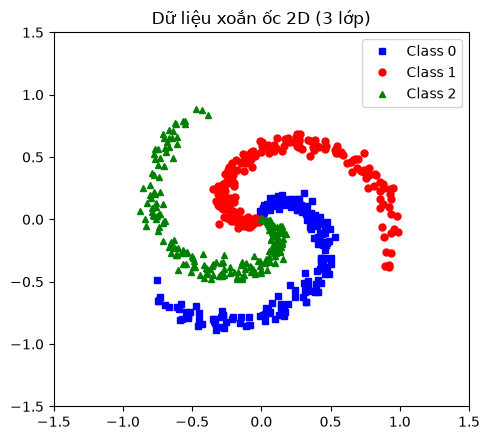

iter 0, loss: 1.098525
iter 1000, loss: 0.128555
iter 2000, loss: 0.074685
iter 3000, loss: 0.042019
iter 4000, loss: 0.031254
iter 5000, loss: 0.025690
iter 6000, loss: 0.022120
iter 7000, loss: 0.019649
iter 8000, loss: 0.017916
iter 9000, loss: 0.016687
Training accuracy: 99.67 %


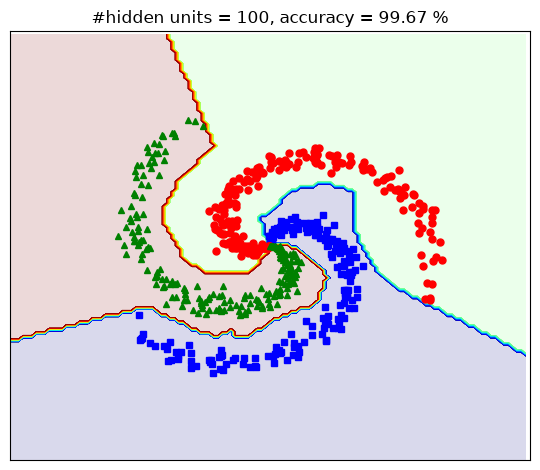

In [1]:
import warnings
warnings.filterwarnings('ignore')
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

# 1. Tạo dữ liệu xoắn ốc 2D (3 lớp, mỗi lớp 200 điểm, không tách tuyến tính)
np.random.seed(42)
N = 200
d = 2
C = 3
X = np.zeros((d, N * C))
y = np.zeros(N * C, dtype='uint8')

for j in range(C):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2
    X[:, ix] = np.c_[r * np.sin(t), r * np.cos(t)].T
    y[ix] = j

plt.figure(figsize=(5, 4.5))
plt.plot(X[0, :N], X[1, :N], 'bs', markersize=5, label='Class 0')
plt.plot(X[0, N:2*N], X[1, N:2*N], 'ro', markersize=5, label='Class 1')
plt.plot(X[0, 2*N:], X[1, 2*N:], 'g^', markersize=5, label='Class 2')
plt.xlim([-1.5, 1.5])
plt.ylim([-1.5, 1.5])
plt.title('Dữ liệu xoắn ốc 2D (3 lớp)')
plt.legend()
plt.tight_layout()
plt.show()

# 2. Các hàm cơ sở của ANN (1 tầng ẩn ReLU + đầu ra Softmax + Cross-Entropy)
def softmax(V):
    e_V = np.exp(V - np.max(V, axis=0, keepdims=True))
    return e_V / e_V.sum(axis=0, keepdims=True)

def ReLU(V):
    return np.maximum(V, 0)

def cost(Y, Yhat):
    return -np.sum(Y * np.log(np.clip(Yhat, 1e-12, 1.0))) / Y.shape[1]

def convert_labels(y_vec, num_classes):
    return sparse.coo_matrix(
        (np.ones_like(y_vec), (y_vec, np.arange(len(y_vec)))),
        shape=(num_classes, len(y_vec))
    ).toarray()

def train_ann(X_tr, y_tr, num_classes, d1=100, eta=1.0, n_iters=10000, seed=42, log_every=0):
    np.random.seed(seed)
    d0, n_samples = X_tr.shape
    Y_oh = convert_labels(y_tr, num_classes)
    W1 = 0.01 * np.random.randn(d0, d1)
    b1 = np.zeros((d1, 1))
    W2 = 0.01 * np.random.randn(d1, num_classes)
    b2 = np.zeros((num_classes, 1))

    for i in range(n_iters):
        Z1 = np.dot(W1.T, X_tr) + b1
        A1 = ReLU(Z1)
        Z2 = np.dot(W2.T, A1) + b2
        Yhat = softmax(Z2)

        if log_every and i % log_every == 0:
            print(f"iter {i}, loss: {cost(Y_oh, Yhat):.6f}")

        E2 = (Yhat - Y_oh) / n_samples
        dW2 = np.dot(A1, E2.T)
        db2 = np.sum(E2, axis=1, keepdims=True)
        E1 = np.dot(W2, E2)
        E1[Z1 <= 0] = 0
        dW1 = np.dot(X_tr, E1.T)
        db1 = np.sum(E1, axis=1, keepdims=True)

        W1 -= eta * dW1
        b1 -= eta * db1
        W2 -= eta * dW2
        b2 -= eta * db2

    return W1, b1, W2, b2

def predict_ann(W1, b1, W2, b2, X_in):
    Z1 = np.dot(W1.T, X_in) + b1
    A1 = ReLU(Z1)
    Z2 = np.dot(W2.T, A1) + b2
    return np.argmax(Z2, axis=0)

# 3. Huấn luyện ANN (d1 = 100, eta = 1, 10000 vòng lặp) và trực quan hóa biên quyết định
W1, b1, W2, b2 = train_ann(X, y, C, d1=100, eta=1.0, n_iters=10000, seed=42, log_every=1000)
pred_spiral = predict_ann(W1, b1, W2, b2, X)
acc_spiral = 100 * np.mean(pred_spiral == y)
print(f"Training accuracy: {acc_spiral:.2f} %")

xm = np.arange(-1.5, 1.5, 0.025)
ym = np.arange(-1.5, 1.5, 0.025)
xx, yy = np.meshgrid(xm, ym)
X0 = np.vstack((xx.ravel(), yy.ravel()))
Z_grid = predict_ann(W1, b1, W2, b2, X0).reshape(xx.shape)

plt.figure(figsize=(5.5, 4.8))
plt.contourf(xx, yy, Z_grid, 200, cmap='jet', alpha=0.15)
plt.plot(X[0, :N], X[1, :N], 'bs', markersize=5)
plt.plot(X[0, N:2*N], X[1, N:2*N], 'ro', markersize=5)
plt.plot(X[0, 2*N:], X[1, 2*N:], 'g^', markersize=5)
plt.xlim([-1.5, 1.5])
plt.ylim([-1.5, 1.5])
plt.xticks([])
plt.yticks([])
plt.title(f'#hidden units = 100, accuracy = {acc_spiral:.2f} %')
plt.tight_layout()
plt.show()


## Bài tập ứng dụng 1: Phân loại dữ liệu hoa Iris


In [2]:
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score

# 1. Đọc dữ liệu Iris và chia mỗi loài 40 mẫu train, 10 mẫu validation
iris_path = 'iris.csv' if os.path.exists('iris.csv') else '../week6/iris.csv'
df_iris = pd.read_csv(iris_path)
X_iris = df_iris.drop(columns=['variety']).values
y_iris = LabelEncoder().fit_transform(df_iris['variety'].values)

X_tr_i, X_va_i, y_tr_i, y_va_i = train_test_split(
    X_iris, y_iris, test_size=30, stratify=y_iris, random_state=42
)
print("Số mẫu mỗi lớp (Train):", np.bincount(y_tr_i), "| (Validation):", np.bincount(y_va_i))

def eval_metrics(y_true, y_pred):
    return (
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, average='macro', zero_division=0),
        recall_score(y_true, y_pred, average='macro', zero_division=0),
    )

def avg_predict_time(fn, n_repeats=100):
    t0 = time.perf_counter()
    for _ in range(n_repeats):
        fn()
    return (time.perf_counter() - t0) / n_repeats

# 2. Huấn luyện ANN (d1 = 100), Softmax Regression và Gaussian Naïve Bayes
t0 = time.perf_counter()
W1_i, b1_i, W2_i, b2_i = train_ann(X_tr_i.T, y_tr_i, 3, d1=100, eta=0.05, n_iters=3000, seed=42)
t_tr_ann = time.perf_counter() - t0
t_pr_ann = avg_predict_time(lambda: predict_ann(W1_i, b1_i, W2_i, b2_i, X_va_i.T))

t0 = time.perf_counter()
lr_iris = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_i, y_tr_i)
t_tr_lr = time.perf_counter() - t0
t_pr_lr = avg_predict_time(lambda: lr_iris.predict(X_va_i))

t0 = time.perf_counter()
nb_iris = GaussianNB().fit(X_tr_i, y_tr_i)
t_tr_nb = time.perf_counter() - t0
t_pr_nb = avg_predict_time(lambda: nb_iris.predict(X_va_i))

rows_iris = []
for name, pred_tr, pred_va, t_tr, t_pr in [
    ('ANN (d1=100)', predict_ann(W1_i, b1_i, W2_i, b2_i, X_tr_i.T), predict_ann(W1_i, b1_i, W2_i, b2_i, X_va_i.T), t_tr_ann, t_pr_ann),
    ('Softmax Regression', lr_iris.predict(X_tr_i), lr_iris.predict(X_va_i), t_tr_lr, t_pr_lr),
    ('Gaussian Naïve Bayes', nb_iris.predict(X_tr_i), nb_iris.predict(X_va_i), t_tr_nb, t_pr_nb),
]:
    tr_acc, tr_pre, tr_rec = eval_metrics(y_tr_i, pred_tr)
    va_acc, va_pre, va_rec = eval_metrics(y_va_i, pred_va)
    rows_iris.append({
        'Mô hình': name,
        'Train Acc': tr_acc, 'Train Prec': tr_pre, 'Train Rec': tr_rec,
        'Val Acc': va_acc, 'Val Prec': va_pre, 'Val Rec': va_rec,
        'Train Time (s)': t_tr, 'Avg Predict Time (ms)': t_pr * 1000
    })

print("\n--- SO SÁNH CÁC MÔ HÌNH TRÊN DỮ LIỆU IRIS ---")
print(pd.DataFrame(rows_iris).to_string(index=False))

# 3. Thay đổi số chiều tầng ẩn d1 lần lượt là 100, 75, 50
rows_hidden = []
for h in [100, 75, 50]:
    t0 = time.perf_counter()
    W1_h, b1_h, W2_h, b2_h = train_ann(X_tr_i.T, y_tr_i, 3, d1=h, eta=0.05, n_iters=3000, seed=42)
    t_tr_h = time.perf_counter() - t0
    t_pr_h = avg_predict_time(lambda: predict_ann(W1_h, b1_h, W2_h, b2_h, X_va_i.T))
    tr_acc, tr_pre, tr_rec = eval_metrics(y_tr_i, predict_ann(W1_h, b1_h, W2_h, b2_h, X_tr_i.T))
    va_acc, va_pre, va_rec = eval_metrics(y_va_i, predict_ann(W1_h, b1_h, W2_h, b2_h, X_va_i.T))
    rows_hidden.append({
        'Hidden units (d1)': h,
        'Train Acc': tr_acc, 'Train Prec': tr_pre, 'Train Rec': tr_rec,
        'Val Acc': va_acc, 'Val Prec': va_pre, 'Val Rec': va_rec,
        'Train Time (s)': t_tr_h, 'Avg Predict Time (ms)': t_pr_h * 1000
    })

print("\n--- THỬ NGHIỆM THAY ĐỔI SỐ CHIỀU TẦNG ẨN ANN (100, 75, 50) ---")
print(pd.DataFrame(rows_hidden).to_string(index=False))


Số mẫu mỗi lớp (Train): [40 40 40] | (Validation): [10 10 10]

--- SO SÁNH CÁC MÔ HÌNH TRÊN DỮ LIỆU IRIS ---
             Mô hình  Train Acc  Train Prec  Train Rec  Val Acc  Val Prec  Val Rec  Train Time (s)  Avg Predict Time (ms)
        ANN (d1=100)   0.983333    0.983333   0.983333 1.000000  1.000000 1.000000        0.215166               0.012373
  Softmax Regression   0.975000    0.975193   0.975000 0.966667  0.969697 0.966667        0.016195               0.101539
Gaussian Naïve Bayes   0.958333    0.958516   0.958333 0.966667  0.969697 0.966667        0.000777               0.108845

--- THỬ NGHIỆM THAY ĐỔI SỐ CHIỀU TẦNG ẨN ANN (100, 75, 50) ---
 Hidden units (d1)  Train Acc  Train Prec  Train Rec  Val Acc  Val Prec  Val Rec  Train Time (s)  Avg Predict Time (ms)
               100   0.983333    0.983333   0.983333      1.0       1.0      1.0        0.213466               0.012310
                75   0.983333    0.983333   0.983333      1.0       1.0      1.0        0.178589   

### Nhận xét (Bài tập ứng dụng 1):
- **So sánh 3 mô hình**: ANN (`d1=100`) đạt độ chính xác cao nhất (Train 98.33%, Validation 100.00%); Softmax Regression (Train 97.50%, Validation 96.67%) và Gaussian Naïve Bayes (Train 95.83%, Validation 96.67%) thấp hơn nhẹ do ranh giới phân tách phi tuyến của ANN linh hoạt hơn và Naïve Bayes giả định độc lập giữa các đặc trưng. Về tốc độ, Gaussian Naïve Bayes (~0.0008s) và Softmax Regression (~0.016s) huấn luyện nhanh hơn nhiều so với ANN lặp Gradient Descent (~0.215s); thời gian dự đoán trung bình của cả 3 mô hình đều rất nhỏ (< 0.2 ms).
- **Ảnh hưởng của số chiều tầng ẩn (`100 -> 75 -> 50`)**: Vì dữ liệu Iris nhỏ và đơn giản (4 đặc trưng, 3 lớp), cả 3 cấu hình `d1 = 100, 75, 50` đều hội tụ tốt và cho cùng kết quả (Train 98.33%, Validation 100.00%). Khi giảm `d1`, số lượng tham số giảm nên thời gian huấn luyện giảm dần (`0.213s -> 0.179s -> 0.145s`) và thời gian dự đoán cũng giảm theo; tăng `d1` quá lớn trên dữ liệu ít mẫu chỉ làm tăng chi phí tính toán mà không cải thiện thêm độ chính xác.

## Ví dụ 2: Giảm chiều PCA và phân loại ảnh chữ số viết tay MNIST


In [3]:
import gzip
from sklearn.decomposition import PCA

def get_mnist_data(images_path, labels_path, num_images=5000, image_size=28):
    with gzip.open(images_path, 'r') as f_img:
        f_img.read(16)
        buf = f_img.read(image_size * image_size * num_images)
        images = np.frombuffer(buf, dtype=np.uint8).astype(np.float32).reshape(num_images, image_size * image_size) / 255.0
    with gzip.open(labels_path, 'r') as f_lbl:
        f_lbl.read(8)
        buf = f_lbl.read(num_images)
        labels = np.frombuffer(buf, dtype=np.uint8).astype(np.int64)
    return images, labels

img_gz = 'train-images-idx3-ubyte.gz' if os.path.exists('train-images-idx3-ubyte.gz') else '../week6/train-images-idx3-ubyte.gz'
lbl_gz = 'train-labels-idx1-ubyte.gz' if os.path.exists('train-labels-idx1-ubyte.gz') else '../week6/train-labels-idx1-ubyte.gz'

X_mnist, y_mnist = get_mnist_data(img_gz, lbl_gz, num_images=5000)

# a. Giảm số chiều dữ liệu xuống còn 125 chiều bằng PCA
pca_mn = PCA(n_components=125, random_state=42)
X_mnist_125 = pca_mn.fit_transform(X_mnist)
print("Kích thước sau giảm chiều PCA:", X_mnist_125.shape)

# b. Chia Train:Test = 0.7:0.3 và áp dụng Multinomial Logistic Regression + ANN (d1=100)
X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(
    X_mnist_125, y_mnist, test_size=0.3, stratify=y_mnist, random_state=42
)

t0 = time.perf_counter()
lr_mn = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_m, y_tr_m)
t_lr_mn = time.perf_counter() - t0
pred_tr_lr_m = lr_mn.predict(X_tr_m)
pred_te_lr_m = lr_mn.predict(X_te_m)

t0 = time.perf_counter()
W1_m1, b1_m1, W2_m1, b2_m1 = train_ann(X_tr_m.T, y_tr_m, 10, d1=100, eta=0.5, n_iters=1000, seed=42)
t_ann_m1 = time.perf_counter() - t0
pred_tr_ann_m1 = predict_ann(W1_m1, b1_m1, W2_m1, b2_m1, X_tr_m.T)
pred_te_ann_m1 = predict_ann(W1_m1, b1_m1, W2_m1, b2_m1, X_te_m.T)

# d. Thực hiện lại mô hình ANN với số chiều tầng ẩn = 150
t0 = time.perf_counter()
W1_m2, b1_m2, W2_m2, b2_m2 = train_ann(X_tr_m.T, y_tr_m, 10, d1=150, eta=0.5, n_iters=1000, seed=42)
t_ann_m2 = time.perf_counter() - t0
pred_tr_ann_m2 = predict_ann(W1_m2, b1_m2, W2_m2, b2_m2, X_tr_m.T)
pred_te_ann_m2 = predict_ann(W1_m2, b1_m2, W2_m2, b2_m2, X_te_m.T)

df_mnist_res = pd.DataFrame([
    {'Mô hình': 'Multinomial Logistic Regression', 'Train Acc': accuracy_score(y_tr_m, pred_tr_lr_m), 'Test Acc': accuracy_score(y_te_m, pred_te_lr_m), 'Thời gian (s)': t_lr_mn},
    {'Mô hình': 'ANN (d1=100)', 'Train Acc': accuracy_score(y_tr_m, pred_tr_ann_m1), 'Test Acc': accuracy_score(y_te_m, pred_te_ann_m1), 'Thời gian (s)': t_ann_m1},
    {'Mô hình': 'ANN (d1=150)', 'Train Acc': accuracy_score(y_tr_m, pred_tr_ann_m2), 'Test Acc': accuracy_score(y_te_m, pred_te_ann_m2), 'Thời gian (s)': t_ann_m2},
])
print("\n--- KẾT QUẢ PHÂN LOẠI MNIST (125 CHIỀU PCA, TRAIN:TEST = 0.7:0.3) ---")
print(df_mnist_res.to_string(index=False))


Kích thước sau giảm chiều PCA: (5000, 125)

--- KẾT QUẢ PHÂN LOẠI MNIST (125 CHIỀU PCA, TRAIN:TEST = 0.7:0.3) ---
                        Mô hình  Train Acc  Test Acc  Thời gian (s)
Multinomial Logistic Regression   0.966286  0.922000       0.053111
                   ANN (d1=100)   0.999429  0.947333       9.307413
                   ANN (d1=150)   0.999714  0.945333      12.370810


### Nhận xét (Ví dụ 2):
- **So sánh Logistic Regression và ANN (`d1=100`)**: Multinomial Logistic Regression huấn luyện rất nhanh (< 0.2s) và đạt Test Accuracy 92.20%. ANN (`d1=100`) tốn thời gian huấn luyện lâu hơn nhiều do lặp Gradient Descent 1000 bước, nhưng nhờ tầng ẩn phi tuyến ReLU nên mô hình học được ranh giới phức tạp hơn, giúp Test Accuracy tăng lên 94.73%.
- **Tăng tầng ẩn lên `d1=150`**: Độ chính xác trên tập Train nhích lên gần như tuyệt đối (99.97% so với 99.94%), nhưng trên tập Test lại giảm nhẹ (94.53% so với 94.73%), cho thấy dấu hiệu bắt đầu quá khớp nhẹ (overfitting) khi tăng số tham số tầng ẩn trên tập dữ liệu kích thước vừa phải.


## Ví dụ 3: Phân tích và phân loại dữ liệu hạt đậu (Dry Bean Dataset)


Kích thước dữ liệu: (13611, 17) | Số lớp: 7 ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


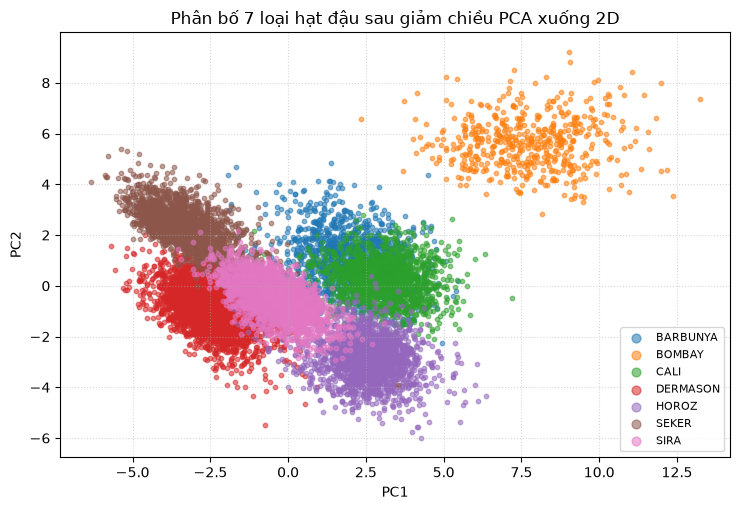


--- KẾT QUẢ ĐÁNH GIÁ TRÊN DỮ LIỆU GỐC (16 CHIỀU) ---
Không gian                   Mô hình  Train Acc  Train Prec  Train Rec  Val Acc  Val Prec  Val Rec
 Gốc (16D)      Gaussian Naïve Bayes   0.898289    0.907124   0.908757 0.896915  0.909414 0.908326
 Gốc (16D) Multinomial Logistic Reg.   0.925895    0.938702   0.936539 0.921890  0.935854 0.933785
 Gốc (16D)      ANN (1 tầng ẩn = 32)   0.933032    0.944628   0.942892 0.927522  0.939558 0.937742

--- HỆ SỐ MÔ HÌNH MULTINOMIAL LOGISTIC REGRESSION (16D) ---
          Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  Eccentricity  ConvexArea  EquivDiameter  Extent  Solidity  roundness  Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  Intercept
BARBUNYA  0.44       0.91            -0.15             1.82         -1.21         -0.25        0.48           0.86    0.30     -1.35      -1.46         0.64         -1.41         -1.85          0.45          1.95       1.03
BOMBAY    2.23       1.36             1.2

In [4]:
from sklearn.preprocessing import StandardScaler

# Đọc dữ liệu Dry Bean (13611 mẫu, 16 đặc trưng, 7 loại hạt đậu)
df_bean = pd.read_csv('Dry_Bean_Dataset.csv')
feature_names_b = df_bean.drop(columns=['Class']).columns.tolist()
X_bean = df_bean.drop(columns=['Class']).values
le_bean = LabelEncoder()
y_bean = le_bean.fit_transform(df_bean['Class'].values)
class_names_b = le_bean.classes_
print("Kích thước dữ liệu:", df_bean.shape, "| Số lớp:", len(class_names_b), list(class_names_b))

# (a) Giảm dữ liệu xuống 2 chiều bằng PCA và hiển thị trực quan phân bố các loại hạt đậu
X_bean_sc_all = StandardScaler().fit_transform(X_bean)
X_bean_2d = PCA(n_components=2, random_state=42).fit_transform(X_bean_sc_all)

plt.figure(figsize=(7.5, 5.2))
for idx, cname in enumerate(class_names_b):
    mask = (y_bean == idx)
    plt.scatter(X_bean_2d[mask, 0], X_bean_2d[mask, 1], s=10, alpha=0.55, label=cname)
plt.title('Phân bố 7 loại hạt đậu sau giảm chiều PCA xuống 2D')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(markerscale=2, fontsize=8)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

# (b) Chia Train:Validation = 7:3 trên dữ liệu gốc (16 chiều) và chuẩn hóa StandardScaler
X_tr_b, X_va_b, y_tr_b, y_va_b = train_test_split(
    X_bean, y_bean, test_size=0.3, stratify=y_bean, random_state=42
)
sc_bean = StandardScaler()
X_tr_bs = sc_bean.fit_transform(X_tr_b)
X_va_bs = sc_bean.transform(X_va_b)

def run_bean_models(X_tr_use, X_va_use, label_space):
    nb = GaussianNB().fit(X_tr_use, y_tr_b)
    lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_use, y_tr_b)
    W1_b, b1_b, W2_b, b2_b = train_ann(X_tr_use.T, y_tr_b, 7, d1=32, eta=0.5, n_iters=1500, seed=42)

    rows = []
    for m_name, p_tr, p_va in [
        ('Gaussian Naïve Bayes', nb.predict(X_tr_use), nb.predict(X_va_use)),
        ('Multinomial Logistic Reg.', lr.predict(X_tr_use), lr.predict(X_va_use)),
        ('ANN (1 tầng ẩn = 32)', predict_ann(W1_b, b1_b, W2_b, b2_b, X_tr_use.T), predict_ann(W1_b, b1_b, W2_b, b2_b, X_va_use.T)),
    ]:
        tr_acc, tr_pre, tr_rec = eval_metrics(y_tr_b, p_tr)
        va_acc, va_pre, va_rec = eval_metrics(y_va_b, p_va)
        rows.append({
            'Không gian': label_space, 'Mô hình': m_name,
            'Train Acc': tr_acc, 'Train Prec': tr_pre, 'Train Rec': tr_rec,
            'Val Acc': va_acc, 'Val Prec': va_pre, 'Val Rec': va_rec
        })
    return pd.DataFrame(rows), lr

df_res_16d, lr_16d = run_bean_models(X_tr_bs, X_va_bs, 'Gốc (16D)')
print("\n--- KẾT QUẢ ĐÁNH GIÁ TRÊN DỮ LIỆU GỐC (16 CHIỀU) ---")
print(df_res_16d.to_string(index=False))

# Hệ số thu được từ Multinomial Logistic Regression (16D)
df_coef_16d = pd.DataFrame(lr_16d.coef_, index=class_names_b, columns=feature_names_b)
df_coef_16d['Intercept'] = lr_16d.intercept_
print("\n--- HỆ SỐ MÔ HÌNH MULTINOMIAL LOGISTIC REGRESSION (16D) ---")
print(df_coef_16d.round(2).to_string())

# (c) Giảm dữ liệu xuống còn 4 chiều bằng PCA và thực hiện lại toàn bộ ý (b)
pca_bean_4 = PCA(n_components=4, random_state=42)
X_tr_b4 = pca_bean_4.fit_transform(X_tr_bs)
X_va_b4 = pca_bean_4.transform(X_va_bs)
print(f"\nTổng phương sai giữ lại với 4 thành phần chính (PCA 4D): {np.sum(pca_bean_4.explained_variance_ratio_):.4f}")

df_res_4d, lr_4d = run_bean_models(X_tr_b4, X_va_b4, 'PCA (4D)')
print("\n--- KẾT QUẢ ĐÁNH GIÁ SAU GIẢM CHIỀU (4 CHIỀU PCA) ---")
print(df_res_4d.to_string(index=False))

df_coef_4d = pd.DataFrame(lr_4d.coef_, index=class_names_b, columns=['PC1', 'PC2', 'PC3', 'PC4'])
df_coef_4d['Intercept'] = lr_4d.intercept_
print("\n--- HỆ SỐ MÔ HÌNH MULTINOMIAL LOGISTIC REGRESSION (4D PCA) ---")
print(df_coef_4d.round(2).to_string())

# So sánh mức độ sụt giảm Accuracy trên Validation giữa 16D và 4D
df_drop = pd.DataFrame({
    'Mô hình': df_res_16d['Mô hình'],
    'Val Acc (16D)': df_res_16d['Val Acc'],
    'Val Acc (4D)': df_res_4d['Val Acc'],
    'Độ giảm Val Acc': df_res_16d['Val Acc'] - df_res_4d['Val Acc'],
    'Độ giảm Val Prec': df_res_16d['Val Prec'] - df_res_4d['Val Prec'],
    'Độ giảm Val Rec': df_res_16d['Val Rec'] - df_res_4d['Val Rec'],
})
print("\n--- SO SÁNH MỨC ĐỘ ẢNH HƯỞNG KHI GIẢM TỪ 16D XUỐNG 4D ---")
print(df_drop.to_string(index=False))


### Giải thích và nhận xét (Ví dụ 3):
- **Ý (a) Trực quan hóa 2D**: Các cụm hạt đậu tách biệt tương đối rõ theo kích thước (`BOMBAY` tách biệt hẳn ở vùng `PC1` lớn), trong khi `DERMASON`, `SIRA`, `CALI` và `HOROZ` có vùng giao thoa ở ranh giới.
- **Ý (b) Trên dữ liệu gốc (16D)**:
  - *Gaussian Naïve Bayes* đạt kết quả thấp nhất (Train 89.83%, Val 89.69%) vì các đặc trưng hình học hạt đậu (`Area`, `Perimeter`, `MajorAxisLength`, `ConvexArea`, `EquivDiameter`) tương quan rất mạnh với nhau, vi phạm giả định độc lập có điều kiện.
  - *Multinomial Logistic Regression* đạt Train 92.59%, Val 92.19% nhờ không đòi hỏi các đặc trưng phải độc lập. Các hệ số chuẩn hóa phản ánh rõ đặc điểm từng loại đậu: `BOMBAY` có hệ số dương lớn nhất ở nhóm kích thước (`ConvexArea +2.24`, `Area +2.23`, `MinorAxisLength +1.80`, `EquivDiameter +1.55`); `DERMASON` (hạt nhỏ nhất) có hệ số âm ở nhóm kích thước (`MajorAxisLength -2.23`, `EquivDiameter -2.22`, `MinorAxisLength -2.07`) và dương lớn ở `ShapeFactor1 (+3.14)`; `HOROZ` nổi bật ở `ShapeFactor1 (+3.00)` và `AspectRation (+2.78)`.
  - *ANN (1 tầng ẩn 32 units, ReLU + Softmax + Cross-Entropy)* đạt độ chính xác cao nhất (Train 93.30%, Val 92.75%; Precision/Recall đều ~93.8–94.5%) và không bị overfitting nhờ học được ranh giới phi tuyến giữa các lớp giao thoa.
- **Ý (c) Khi giảm xuống 4 chiều PCA**: 4 thành phần chính giữ lại được 95.09% tổng phương sai, nhưng việc nén tuyến tính từ 16 chiều xuống 4 chiều làm mất thông tin phân tách tinh tế nên hiệu năng cả 3 mô hình đều giảm (~3.26%–3.43% Val Acc). Trong đó, **ANN (32 units)** bị ảnh hưởng nhiều nhất về Accuracy và Recall (Val Acc giảm `3.43%`, Val Recall giảm `4.34%`) vì mất đi phần lớn thông tin chi tiết ở các thành phần sau để tận dụng khả năng phân tách phi tuyến.

## Ví dụ 4: Giảm chiều PCA và phân loại ảnh khuôn mặt (Yale Faces)


Số ảnh: 165, Kích thước ảnh: (243, 320), Số chiều gốc D = 77760
Kích thước sau giảm chiều PCA: (165, 125)

--- KẾT QUẢ PHÂN LOẠI 15 KHUÔN MẶT (125 CHIỀU PCA, TRAIN:TEST = 0.7:0.3) ---
                        Mô hình  Train Acc  Test Acc
Multinomial Logistic Regression        1.0      0.88
           Gaussian Naïve Bayes        1.0      0.66
                   ANN (d1=100)        1.0      0.76


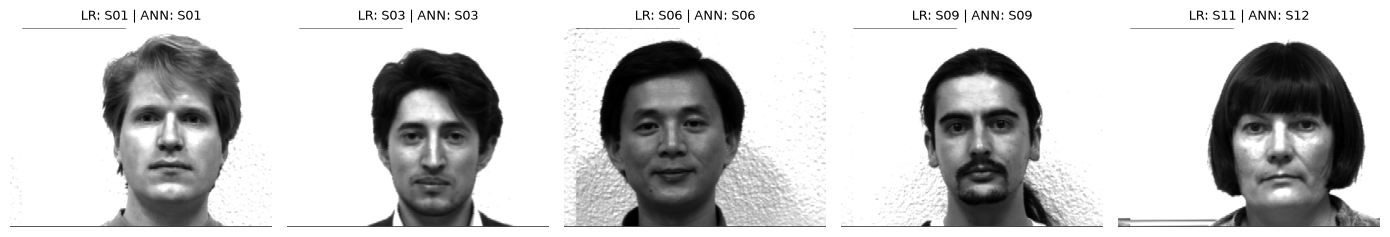


--- DỰ ĐOÁN NHÓM CHO 5 ẢNH CHÂN DUNG MỚI ---
                      Ảnh test Logistic Reg. GaussianNB ANN (d1=100)
test_portrait_01_subject01.png     subject01  subject01    subject01
test_portrait_02_subject03.png     subject03  subject03    subject03
test_portrait_03_subject06.png     subject06  subject06    subject06
test_portrait_04_subject09.png     subject09  subject09    subject09
test_portrait_05_subject11.png     subject11  subject11    subject12


In [5]:
import zipfile
import cv2

# 1. Đọc 165 ảnh khuôn mặt (15 người x 11 trạng thái) từ face_data.zip
states = ['centerlight', 'glasses', 'happy', 'leftlight', 'noglasses',
          'normal', 'rightlight', 'sad', 'sleepy', 'surprised', 'wink']

imgs, labels_person = [], []
with zipfile.ZipFile('face_data.zip', 'r') as z:
    for person_id in range(1, 16):
        for state in states:
            fn = f'face_data/subject{str(person_id).zfill(2)}.{state}.png'
            raw = np.frombuffer(z.read(fn), np.uint8)
            im = cv2.imdecode(raw, cv2.IMREAD_GRAYSCALE)
            h_img, w_img = im.shape
            imgs.append(im.reshape(-1))
            labels_person.append(person_id - 1)

X_faces = np.array(imgs, dtype=np.float64) / 255.0   # (165, D)
y_faces = np.array(labels_person)
print(f"Số ảnh: {X_faces.shape[0]}, Kích thước ảnh: ({h_img}, {w_img}), Số chiều gốc D = {X_faces.shape[1]}")

# (i) Giảm số chiều dữ liệu xuống còn 125 bằng PCA
pca_faces = PCA(n_components=125, random_state=42)
Z_faces = pca_faces.fit_transform(X_faces)
print("Kích thước sau giảm chiều PCA:", Z_faces.shape)

# (ii) Chia train:test = 0.7:0.3 và áp dụng Logistic Regression, GaussianNB, ANN
X_tr_f, X_te_f, y_tr_f, y_te_f = train_test_split(
    Z_faces, y_faces, test_size=0.3, stratify=y_faces, random_state=42
)

lr_face = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_f, y_tr_f)
nb_face = GaussianNB().fit(X_tr_f, y_tr_f)
W1_f, b1_f, W2_f, b2_f = train_ann(X_tr_f.T, y_tr_f, 15, d1=100, eta=0.1, n_iters=3000, seed=42)

df_face_res = pd.DataFrame([
    {'Mô hình': 'Multinomial Logistic Regression', 'Train Acc': accuracy_score(y_tr_f, lr_face.predict(X_tr_f)), 'Test Acc': accuracy_score(y_te_f, lr_face.predict(X_te_f))},
    {'Mô hình': 'Gaussian Naïve Bayes', 'Train Acc': accuracy_score(y_tr_f, nb_face.predict(X_tr_f)), 'Test Acc': accuracy_score(y_te_f, nb_face.predict(X_te_f))},
    {'Mô hình': 'ANN (d1=100)', 'Train Acc': accuracy_score(y_tr_f, predict_ann(W1_f, b1_f, W2_f, b2_f, X_tr_f.T)), 'Test Acc': accuracy_score(y_te_f, predict_ann(W1_f, b1_f, W2_f, b2_f, X_te_f.T))},
])
print("\n--- KẾT QUẢ PHÂN LOẠI 15 KHUÔN MẶT (125 CHIỀU PCA, TRAIN:TEST = 0.7:0.3) ---")
print(df_face_res.to_string(index=False))

# (iii) Huấn luyện trên toàn bộ 165 ảnh và thử nghiệm với 5 ảnh chân dung mới
lr_face_full = LogisticRegression(max_iter=1000, random_state=42).fit(Z_faces, y_faces)
nb_face_full = GaussianNB().fit(Z_faces, y_faces)
W1_ff, b1_ff, W2_ff, b2_ff = train_ann(Z_faces.T, y_faces, 15, d1=100, eta=0.1, n_iters=3000, seed=42)

test_dir = 'test_portraits' if os.path.exists('test_portraits') else '../week6/test_portraits'
test_files = sorted([f for f in os.listdir(test_dir) if f.endswith('.png')])

pred_rows = []
plt.figure(figsize=(14, 3.2))
for i, fn in enumerate(test_files):
    im_t = cv2.imread(os.path.join(test_dir, fn), cv2.IMREAD_GRAYSCALE)
    if im_t.shape != (h_img, w_img):
        im_t = cv2.resize(im_t, (w_img, h_img))
    z_t = pca_faces.transform(im_t.reshape(1, -1).astype(np.float64) / 255.0)

    p_lr = lr_face_full.predict(z_t)[0] + 1
    p_nb = nb_face_full.predict(z_t)[0] + 1
    p_ann = predict_ann(W1_ff, b1_ff, W2_ff, b2_ff, z_t.T)[0] + 1

    pred_rows.append({
        'Ảnh test': fn,
        'Logistic Reg.': f'subject{p_lr:02d}',
        'GaussianNB': f'subject{p_nb:02d}',
        'ANN (d1=100)': f'subject{p_ann:02d}'
    })

    plt.subplot(1, 5, i + 1)
    plt.imshow(im_t, cmap='gray')
    plt.title(f"LR: S{p_lr:02d} | ANN: S{p_ann:02d}", fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

print("\n--- DỰ ĐOÁN NHÓM CHO 5 ẢNH CHÂN DUNG MỚI ---")
print(pd.DataFrame(pred_rows).to_string(index=False))


### Nhận xét (Ví dụ 4):
- **Trên tập dữ liệu 165 ảnh (125 chiều PCA)**: Cả 3 mô hình đều đạt 100% trên tập Train; trên tập Test, Multinomial Logistic Regression đạt độ chính xác cao nhất (88.00%), tiếp theo là ANN (76.00%), và Gaussian Naïve Bayes thấp nhất (66.00%) do số lượng mẫu huấn luyện ít (115 ảnh cho 15 lớp) khiến mô hình phi tuyến nhiều tham số như ANN dễ overfitting hơn mô hình tuyến tính, còn Naïve Bayes chịu ảnh hưởng của giả định phân phối độc lập.
- **Thử nghiệm 5 ảnh chân dung lệch phải**: Khi huấn luyện trên toàn bộ 165 ảnh, Multinomial Logistic Regression và Gaussian Naïve Bayes đều nhận diện đúng cả 5/5 người (`subject01, 03, 06, 09, 11`), trong khi ANN nhận diện đúng 4/5 ảnh (nhầm `subject11` thành `subject12`).